<a href="https://colab.research.google.com/github/MinjiKim04/Data-Analysis-with-Open-Source/blob/main/%EC%98%A4%ED%94%88%EC%86%8C%EC%8A%A4_%EB%8D%B0%EC%9D%B4%ED%84%B0_%EB%B6%84%EC%84%9D_13%EA%B0%95.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 13강 반정형 데이터 분석 : 게시판 글 데이터 활용

### 목표

방송통신대학교 학생 게시판의 글 제목을 수집하고 분석하여, 반정형 데이터의 수집부터 텍스트 분석까지 전체 과정을 실습

### 분석 프로세스 개요

1. 데이터 수집
  - selenium을 활용한 웹 페이지 접근
  - lxml을 이용한 HTML 파싱
  - 게시글 제목 추출

2. 텍스트 데이터 전처리
  - 정규식을 활용한 텍스트 정제
  - 형태소 분석을 통한 명사 추출

3. 키워드 분석
  - 단어 빈도 분석
  - 워드 클라우드 생성
  - 주요 키워드 추출

4. 텍스트 분류 및 시각화
  - LLM을 활용한 텍스트 분류
  - 분류 결과 시각화
  - 인사이트 도출


# 주의 : 런타임 GPU 로 설정 필요

In [1]:
# LLM 처리를 위한 VLLM 설치 (오래걸리는 작업이므로 미리 실행!)
#!pip install vllm==0.9.0 transformers==4.52.4
!pip install vllm
# 필요 시 세션 재시작

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 336.4/336.4 MB 48.7 MB/s  0:00:05
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 94.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.1/62.1 MB 64.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 556.0/556.0 kB 27.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 126.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 98.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 66.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.7/91.7 MB 64.1 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 92.0/92.0 MB 67.1 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 782.6/782.6 kB 45.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 76.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.2/43.2 MB 66.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 729.6/729.6 kB 41.4 MB/s  0:00:00
   ━━━━━━━━━━

In [1]:
# 한글 처리를 위한 matplotlib 설정 (1)

!sudo apt-get install -y fonts-nanum
!sudo fc-cache –fv
!rm ~/.cache/matplotlib -rf

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  fonts-nanum
0 upgraded, 1 newly installed, 0 to remove and 33 not upgraded.
Need to get 10.3 MB of archives.
After this operation, 34.1 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/universe amd64 fonts-nanum all 20200506-1 [10.3 MB]
Fetched 10.3 MB in 3s (3,250 kB/s)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
Selecting previously unselected package fonts-nanum.
(Reading database ... 127324 files and

- 런타임 -> 세션 다시 시작

In [1]:
# 한글 처리를 위한 matplotlib 설정 (2)

import matplotlib.pyplot as plt
plt.rc('font', family='NanumBarunGothic')

# 1. 데이터 수집 및 전처리

## 13-1 웹 스크래핑 라이브러리 설치

In [2]:
!pip install google-colab-selenium lxml

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 16.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 35.8 MB/s  0:00:00
  Attempting uninstall: urllib3
    Found existing installation: urllib3 2.5.0
    Uninstalling urllib3-2.5.0:
      Successfully uninstalled urllib3-2.5.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [google-colab-selenium]


## 13-2 웹 스크래핑 함수 정의 및 실행

In [4]:
import google_colab_selenium as gs
from lxml import html

## URL로부터 페이지 내용 가져오기
def get_page(driver, url): # driver: 가상의 웹 브라우저
    # url 페이지로 이동
    driver.get(url)
    # 해당 페이지의 html을 page_content로 저장
    page_content = driver.page_source
    # page_content를 lxml의 html 객체로 변환하고 tree로 저장
    tree = html.fromstring(page_content) # 트리 탐색
    return tree

## HTML 트리에서 제목 추출
def extract_titles(tree):
    ## td-subject를 클래스로 가지는 td 태그 > a태그 > strong > text() 을 xpath로 구하고 titles로 저장
    titles = tree.xpath('//td[@class="td-subject"]/a/strong/text()')
    return titles

## 제목 목록 출력
def print_titles(titles):
    for title in titles:
        print(title)

## Chrome 드라이버 초기화
driver = gs.Chrome()

## 컴퓨터과학과 게시판 첫번째 페이지 제목 데이터 수집
board_name = '컴퓨터과학과'
board_url = 'https://cs.knou.ac.kr/cs1/4794/subview.do'
tree = get_page(driver, board_url)
titles = extract_titles(tree)
print_titles(titles)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

2학기 기말과제물 A+ 4단계 꿀~ 팁(필독!)
[GDG Daejeon] 11/28(토) DevFest 2026 대전
방송대 2026학년도 2학기 기말시험 신청 및 학습 전략
풍수지리 신입회원 모심    
🍀크로바 네이버 카페 🍀크로바 기출문제 카페 🍀크로바 학사공지 전용 단톡방 
📢우수 학습자 인터뷰 영상📢온라인 강의 노하우 팁📢왜 공부해요?📢방진이📢방송대를 
🔔방송대 공지사항 카톡 알리미🔔과제길잡이🔔기출과제🔔과제족보🔔기출문제🔔요점정리🔔
2026 이노베이션아카데미 성과 공유 컨퍼런스 개최 안내
LG CNS 현직자와 함께하는 "AI 트렌드 온라인 특강"
[한국능률협회] 미래내일 프로젝트 참여자 모집


## 13-3 다중 페이지 데이터 수집 및 데이터프레임 생성

In [5]:
from selenium.webdriver.common.by import By
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC
import pandas as pd

## 다음 페이지로 이동하고 tree 정보 반환
def move_to_next_page(driver):

    # _listNext 클래스를 기준으로 엘리먼트 선택 셀레늄으로 다음페이지 버튼 클릭 학습
    next_page_link = driver.find_element(By.CLASS_NAME, "_listNext")
    if next_page_link and next_page_link.is_enabled():

        # 다음 페이지 버튼 클릭
        next_page_link.click()
        WebDriverWait(driver, 10).until(
            EC.presence_of_element_located((By.CLASS_NAME, "board-table"))
        ) # 로딩이 잘 됐는지 확인하는 유틸리티, 최대 10초 대기 board-table이 보이기 전까지 대기
        page_content = driver.page_source
        tree = html.fromstring(page_content) #트리로 변환 및 반환
        return tree
    else:
        return None

## 여러 페이지에서 게시물 제목 가져오기
def get_board_titles(url, pages, verbose=False): # verbose: 상태변경 알림 옵션
    driver = gs.Chrome()
    board_titles = []
    for page in pages:
        if verbose:
          print(f"=== 페이지 {page} 처리중입니다. ===")
        if page == 1:
            # 13-2 에서 작성한 get_page 함수를 이용하여 현재 페이지 tree 구하기
            tree = get_page(driver, url)
        else:
            # 다음 페이지로 이동하고 해당 페이지 tree 구하기
            tree = move_to_next_page(driver)
        if tree is not None:
            titles = extract_titles(tree)
            board_titles.extend(titles)
            if verbose:
              print_titles(titles)
    driver.quit()  # Chrome 드라이버 종료
    return board_titles

## 컴퓨터과학과 게시판 1 페이지 ~ 10 페이지의 제목 데이터 수집
board_name = '컴퓨터과학과'
board_url = 'https://cs.knou.ac.kr/cs1/4794/subview.do'
board_titles = get_board_titles(url=board_url, pages=range(1,11), verbose=True)
## 컴퓨터과학과 제목 데이터프레임 생성
cs_df = pd.DataFrame(data = {'제목': board_titles})

<IPython.core.display.Javascript object>

=== 페이지 1 처리중입니다. ===
2학기 기말과제물 A+ 4단계 꿀~ 팁(필독!)
[GDG Daejeon] 11/28(토) DevFest 2026 대전
방송대 2026학년도 2학기 기말시험 신청 및 학습 전략
풍수지리 신입회원 모심    
🍀크로바 네이버 카페 🍀크로바 기출문제 카페 🍀크로바 학사공지 전용 단톡방 
📢우수 학습자 인터뷰 영상📢온라인 강의 노하우 팁📢왜 공부해요?📢방진이📢방송대를 
🔔방송대 공지사항 카톡 알리미🔔과제길잡이🔔기출과제🔔과제족보🔔기출문제🔔요점정리🔔
2026 이노베이션아카데미 성과 공유 컨퍼런스 개최 안내
LG CNS 현직자와 함께하는 "AI 트렌드 온라인 특강"
[한국능률협회] 미래내일 프로젝트 참여자 모집
=== 페이지 2 처리중입니다. ===
SSAFY에서 AI도, 취업 경쟁력도 완성하세요, SSAFY 17기 모집시작!
[청년취업사관학교] 교육비 무료 / AI Harness Engineering 기반 헬스케어
[인권센터] ✈️ 아차 싶다! 그때 그 말, 괜찮은 줄 알았는데… 인천지역대학 특강 신청
2026학년도 2학기 기말시험 시행 공고 / 크로바 기출문제 카페
📢우수 학습자 인터뷰 영상📢온라인 강의 노하우 팁📢왜 공부해요?📢방진이📢방송대를 
🔔방송대 공지사항 카톡 알리미🔔과제길잡이🔔기출과제🔔과제족보🔔기출문제🔔요점정리🔔
가야 역사 풍수지리 답사 에 선착순 31명 초청 합니다!     
연극치료 임상실습 참여자 모집
<<영어연극회 "끼" 47회 정기공연 무료 초대 >>
웹 소설 '연극치료사' 
=== 페이지 3 처리중입니다. ===
과제물, 학습자료 가기
●동우회/서울남부● 누구나 쉬운~피클볼, 파크골프, 양궁, 건강체조, 그외~
「SK쉴더스 Rookies 7기」 교육과정
📢우수 학습자 인터뷰 영상📢온라인 강의 노하우 팁📢왜 공부해요?📢방진이📢방송대를 
🔔방송대 공지사항 카톡 알리미🔔과제길잡이🔔기출과제🔔과제족보🔔기출문제🔔요점정리🔔
미래내일 일경험 기업 실무 프로젝트 참여자 모집 (~9/20)
2026 AI 트렌드 온라인 특강
🚨

# 2. 텍스트 데이터 전처리

## 13-4 정규식을 활용한 텍스트 정제

In [6]:
import re

## 텍스트 정제 함수
def clean_text(text):
    if isinstance(text, str):
       # 특수 문자 제거 regex (영어 소문자, 영어 대문자, 숫자, 한글, 공백글자만 허용)
       text = re.sub(r'[^a-zA-Z0-9가-힣\s]', '', text) # 레귤러 익스프레션 ^: 표기된것 외 나머지 제외 -> 없는 문자로 치환함

       # HTML 태그 제거 regex
       text = re.sub(r'<[^>]*>', '', text)

       # 소문자로 변환 python 함수
       text = text.lower()
       return text
    else:
        return ""

## 데이터프레임 정제 함수
def clean_df(df):
  if not df.empty:
      df['정제된 제목'] = df['제목'].apply(clean_text)

## cs_df에 정제 함수 적용
clean_df(cs_df)
cs_df

,제목,정제된 제목
0,2학기 기말과제물 A+ 4단계 꿀~ 팁(필독!),2학기 기말과제물 a 4단계 꿀 팁필독
1,[GDG Daejeon] 11/28(토) DevFest 2026 대전,gdg daejeon 1128토 devfest 2026 대전
2,방송대 2026학년도 2학기 기말시험 신청 및 학습 전략,방송대 2026학년도 2학기 기말시험 신청 및 학습 전략
3,풍수지리 신입회원 모심,풍수지리 신입회원 모심
4,🍀크로바 네이버 카페 🍀크로바 기출문제 카페 🍀크로바 학사공지 전용 단톡방,크로바 네이버 카페 크로바 기출문제 카페 크로바 학사공지 전용 단톡방
...,...,...
95,📢방송통신대🔔네이버 대표카페 📌참고만해🚨기출문제🔥요점정리💥학점비서✨교재장터🎉,방송통신대네이버 대표카페 참고만해기출문제요점정리학점비서교재장터
96,연극동아리 (극예술연구회) 49기 신입 회원 모집,연극동아리 극예술연구회 49기 신입 회원 모집
97,신. 편입생 형성평가와 효과적인 학습 제안,신 편입생 형성평가와 효과적인 학습 제안
98,🍀크로바 네이버 카페,크로바 네이버 카페


## 13-5 형태소 분석기 설치 및 실행 예시

In [7]:
## Kiwi 형태소 분석기 설치
!pip install kiwipiepy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.9/87.9 MB 50.1 MB/s  0:00:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.7/11.7 MB 104.3 MB/s  0:00:00
  Created wheel for kiwipiepy_model: filename=kiwipiepy_model-0.24.0-py3-none-any.whl size=87973828 sha256=281cd5cbc3b0dbecdf795463e9774e8dd1da115cdb176352a4650b79175a6157
  Stored in directory: /root/.cache/pip/wheels/1e/08/d4/4ff00b71c6b738e5308a0867385c986a743e5307c5206da985
Successfully built kiwipiepy_model
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [kiwipiepy]


In [8]:
from kiwipiepy import Kiwi

## 형태소 분석기 초기화 및 사용자 사전 추가
kiwi = Kiwi()
kiwi.add_user_word('방송대', 'NNP')

## 문장 형태소 분석 결과 출력
kiwi.analyze('안녕하세요 저는 방송대 학생입니다.')[0][0]

[Token(form='안녕', tag='NNG', start=0, len=2),
 Token(form='하', tag='XSA', start=2, len=1),
 Token(form='세요', tag='EF', start=3, len=2),
 Token(form='저', tag='NP', start=6, len=1),
 Token(form='는', tag='JX', start=7, len=1),
 Token(form='방송대', tag='NNP', start=9, len=3),
 Token(form='학생', tag='NNG', start=13, len=2),
 Token(form='이', tag='VCP', start=15, len=1),
 Token(form='ᆸ니다', tag='EF', start=15, len=3),
 Token(form='.', tag='SF', start=18, len=1)]

## 13-6 형태소 분석을 통한 품사 분리

In [9]:
from kiwipiepy import Kiwi

## 형태소 분석기 초기화 및 사용자 사전 추가
kiwi = Kiwi()
kiwi.add_user_word('방송대', 'NNP')
kiwi.add_user_word('방통대', 'NNP')

## 텍스트 형태소 분석 함수
def analyze_morphemes(text):
    if isinstance(text, str):
       result = kiwi.analyze(text)

       morphemes = []
       for token in result[0][0]:
            ## 형태소(form)와 품사(tag) 정보를 튜플로 morphemes에 추가
            morphemes.append((token.form, token.tag))
       return morphemes
    else:
        return []

## 데이터프레임에 형태소 분석 적용 함수
def pos_df(df):
  if not df.empty:
      # `정제된 제목` 칼럼의 값에 analyze_morphemes 함수를 적용하고 결과를 `형태소 분석 결과` 칼럼에 저장
      df['형태소 분석 결과'] = df['정제된 제목'].apply(analyze_morphemes)

## 형태소 분석 적용
pos_df(cs_df)
cs_df

,제목,정제된 제목,형태소 분석 결과
0,2학기 기말과제물 A+ 4단계 꿀~ 팁(필독!),2학기 기말과제물 a 4단계 꿀 팁필독,"[(2, SN), (학기, NNG), (기말, NNG), (과제물, NNG), (a..."
1,[GDG Daejeon] 11/28(토) DevFest 2026 대전,gdg daejeon 1128토 devfest 2026 대전,"[(gdg, SL), (daejeon, SL), (1128, SN), (토, NNG..."
2,방송대 2026학년도 2학기 기말시험 신청 및 학습 전략,방송대 2026학년도 2학기 기말시험 신청 및 학습 전략,"[(방송대, NNP), (2026, SN), (학년도, NNG), (2, SN), ..."
3,풍수지리 신입회원 모심,풍수지리 신입회원 모심,"[(풍수지리, NNG), (신입, NNG), (회원, NNG), (모시, VV), ..."
4,🍀크로바 네이버 카페 🍀크로바 기출문제 카페 🍀크로바 학사공지 전용 단톡방,크로바 네이버 카페 크로바 기출문제 카페 크로바 학사공지 전용 단톡방,"[(크로바, NNP), (네이버, NNP), (카페, NNG), (크로바, NNG)..."
...,...,...,...
95,📢방송통신대🔔네이버 대표카페 📌참고만해🚨기출문제🔥요점정리💥학점비서✨교재장터🎉,방송통신대네이버 대표카페 참고만해기출문제요점정리학점비서교재장터,"[(방송, NNG), (통신, NNG), (대, XPN), (네이버, NNP), (..."
96,연극동아리 (극예술연구회) 49기 신입 회원 모집,연극동아리 극예술연구회 49기 신입 회원 모집,"[(연극, NNG), (동아리, NNG), (극예술연구회, NNP), (49, SN..."
97,신. 편입생 형성평가와 효과적인 학습 제안,신 편입생 형성평가와 효과적인 학습 제안,"[(신, XPN), (편입, NNG), (생, XSN), (형성, NNG), (평가..."
98,🍀크로바 네이버 카페,크로바 네이버 카페,"[(크로바, NNP), (네이버, NNP), (카페, NNG)]"


## 13-7 명사 추출

In [10]:
## 형태소 분석 결과에서 명사 추출
def extract_nouns(morphemes):
  # 형태소가 NNG (일반명사), NNP (고유명사) 인 word를 nouns에 저장
  nouns = [word for word, tag in morphemes if tag in ['NNG', 'NNP']]
  return nouns

## 데이터프레임에 명사 추출 적용
def noun_df(df):
  if not df.empty:
      df['명사'] = df['형태소 분석 결과'].apply(extract_nouns)

## 명사 추출 적용
noun_df(cs_df)
cs_df

,제목,정제된 제목,형태소 분석 결과,명사
0,2학기 기말과제물 A+ 4단계 꿀~ 팁(필독!),2학기 기말과제물 a 4단계 꿀 팁필독,"[(2, SN), (학기, NNG), (기말, NNG), (과제물, NNG), (a...","[학기, 기말, 과제물, 단계, 꿀, 팁, 필독]"
1,[GDG Daejeon] 11/28(토) DevFest 2026 대전,gdg daejeon 1128토 devfest 2026 대전,"[(gdg, SL), (daejeon, SL), (1128, SN), (토, NNG...","[토, 대전]"
2,방송대 2026학년도 2학기 기말시험 신청 및 학습 전략,방송대 2026학년도 2학기 기말시험 신청 및 학습 전략,"[(방송대, NNP), (2026, SN), (학년도, NNG), (2, SN), ...","[방송대, 학년도, 학기, 기말, 시험, 신청, 학습, 전략]"
3,풍수지리 신입회원 모심,풍수지리 신입회원 모심,"[(풍수지리, NNG), (신입, NNG), (회원, NNG), (모시, VV), ...","[풍수지리, 신입, 회원]"
4,🍀크로바 네이버 카페 🍀크로바 기출문제 카페 🍀크로바 학사공지 전용 단톡방,크로바 네이버 카페 크로바 기출문제 카페 크로바 학사공지 전용 단톡방,"[(크로바, NNP), (네이버, NNP), (카페, NNG), (크로바, NNG)...","[크로바, 네이버, 카페, 크로바, 기출, 문제, 카페, 크로바, 학사, 공지, 전..."
...,...,...,...,...
95,📢방송통신대🔔네이버 대표카페 📌참고만해🚨기출문제🔥요점정리💥학점비서✨교재장터🎉,방송통신대네이버 대표카페 참고만해기출문제요점정리학점비서교재장터,"[(방송, NNG), (통신, NNG), (대, XPN), (네이버, NNP), (...","[방송, 통신, 네이버, 대표, 카페, 참고, 기출, 문제, 요점, 정리, 학점, ..."
96,연극동아리 (극예술연구회) 49기 신입 회원 모집,연극동아리 극예술연구회 49기 신입 회원 모집,"[(연극, NNG), (동아리, NNG), (극예술연구회, NNP), (49, SN...","[연극, 동아리, 극예술연구회, 기, 신입, 회원, 모집]"
97,신. 편입생 형성평가와 효과적인 학습 제안,신 편입생 형성평가와 효과적인 학습 제안,"[(신, XPN), (편입, NNG), (생, XSN), (형성, NNG), (평가...","[편입, 형성, 평가, 효과, 학습, 제안]"
98,🍀크로바 네이버 카페,크로바 네이버 카페,"[(크로바, NNP), (네이버, NNP), (카페, NNG)]","[크로바, 네이버, 카페]"


## 13-8 데이터 전처리 통합 함수 정의

In [11]:
## 데이터프레임 전처리 통합 함수
def preprocessing_df(df):
  clean_df(df) ## 텍스트 정제 적용
  pos_df(df) ## 형태소 분석 적용
  noun_df(df) ## 명사 추출 적용

# 3. 키워드 분석

## 13-9 단어 빈도 계산

In [12]:
from collections import Counter

## 데이터프레임에서 단어 빈도 계산
def get_word_count(df):
    if not df.empty:
        # 모든 명사의 리스트를 구함
        all_nouns = df['명사'].sum()
        # 모든 명사들에 대한 Counter 객체(빈도 정보) 를 반환
        return Counter(all_nouns)

## cs_df의 단어 빈도 계산
word_count = get_word_count(cs_df) # 카운터 객체가 들어가게 됨
print("단어 빈도:")
## 상위 30개 단어(most_common)의 빈도 출력
for word, freq in word_count.most_common(30):
    print(f"{word}: {freq}")

단어 빈도:
모집: 39
연극: 30
신입: 26
회원: 26
동아리: 24
방송대: 19
기: 18
카페: 13
기출: 13
문제: 13
극예술: 13
연구회: 13
네이버: 11
정리: 10
대표: 10
온라인: 9
요점: 9
극예술연구회: 9
참고: 9
학기: 7
공지: 7
인터뷰: 7
전통: 7
크로바: 6
공부: 6
사항: 6
웹: 6
소설: 6
치료사: 6
교재: 6


## 13-10 워드클라우드 생성 및 시각화

In [13]:
## WordCloud 라이브러리 설치
!pip install wordcloud

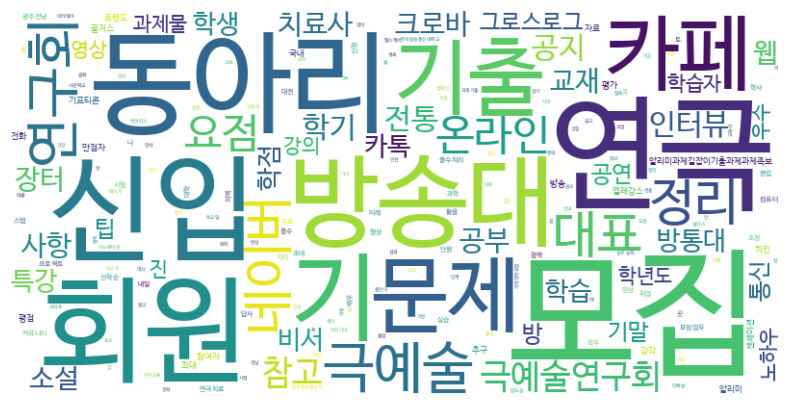

In [14]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

## 단어 빈도를 바탕으로 워드클라우드 생성 및 표시
def plot_wordcloud(word_count):
    ## 워드 클라우드 생성
    wordcloud = WordCloud( # 생성자 내에 그림 스타일 지정
        width=800,
        height=400,
        background_color='white',
        colormap='viridis',
        font_path='/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf' ## 한글 폰트 경로 지정
        ).generate_from_frequencies(word_count) # word_count의 빈도 정보를 이용하여 생성

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear') ## 이미지 표시
    plt.axis("off") ## 축 비활성화
    plt.show() ## 그래프 표시

## cs_df에서 단어 빈도 계산
word_count = get_word_count(cs_df)
## 워드클라우드 생성 및 표시
plot_wordcloud(word_count)

## 13-11 다른 학과의 워드 클라우드 생성

<IPython.core.display.Javascript object>

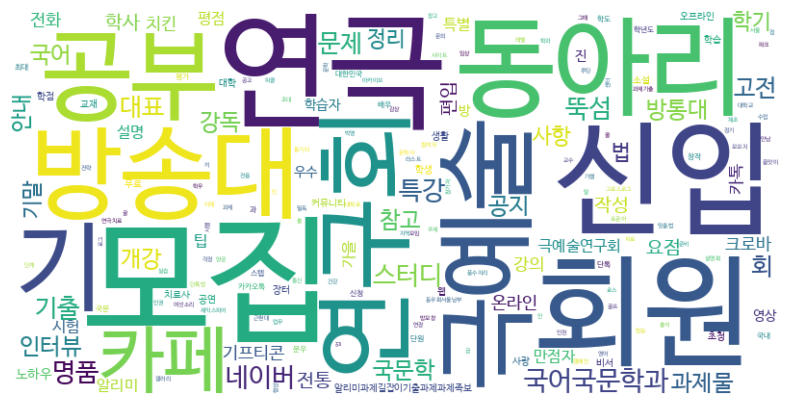

In [15]:
board_name = '국어국문학과'
board_url = 'https://korean.knou.ac.kr/korean/5323/subview.do'
board_titles = get_board_titles(url=board_url, pages=range(1,11), verbose=False)
ko_df = pd.DataFrame(data = {'제목': board_titles})
preprocessing_df(ko_df)
word_count = get_word_count(ko_df)
plot_wordcloud(word_count)

<IPython.core.display.Javascript object>

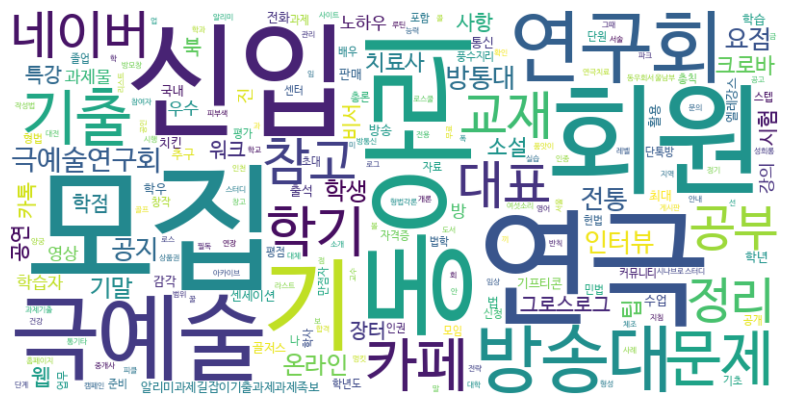

In [16]:
board_name = '법학과'
board_url = 'https://law.knou.ac.kr/law/5176/subview.do'
board_titles = get_board_titles(url=board_url, pages=range(1,11), verbose=False)
law_df = pd.DataFrame(data = {'제목': board_titles})
preprocessing_df(law_df)
word_count = get_word_count(law_df)
plot_wordcloud(word_count)

# 4. 텍스트 분류 및 시각화

## 13-12 VLLM 라이브러리 설치 및 LLM 모델 로드

주의
- 런타임 유형 : GPU
- 라이브러리 설치 및 모델 다운로드에 수 분(>6분)의 시간이 소요됩니다.


In [17]:
from vllm import LLM

## LLM 모델 로드 및 설정
llm = LLM(
    model="LGAI-EXAONE/EXAONE-3.5-2.4B-Instruct", # 20억정도 파라미터로 구성된 소형 모델
    tensor_parallel_size=1,
    dtype="half",
    gpu_memory_utilization=0.6,
    max_model_len=32000,
    trust_remote_code=True
)

W1112 05:23:42.807000 6207 torch/_opaque_base.py:6] torch._opaque_base is deprecated, use torch._custom_class_base instead
W1112 05:23:42.809000 6207 torch/_library/opaque_object.py:288] register_opaque_type is deprecated, use register_custom_class instead
W1112 05:23:42.811000 6207 torch/_library/opaque_object.py:211] typ='value' is deprecated, use typ='constant' instead


(MainProcess pid=6207) INFO 11-12 05:24:00 [startup.py:96] non-default args: {'trust_remote_code': True, 'dtype': 'half', 'max_model_len': 32000, 'gpu_memory_utilization': 0.6, 'disable_log_stats': True, 'model': 'LGAI-EXAONE/EXAONE-3.5-2.4B-Instruct'}


config.json:   0%|          | 0.00/1.04k [00:00<?, ?B/s]

configuration_exaone.py:   0%|          | 0.00/11.3k [00:00<?, ?B/s]

[transformers] A new version of the following files was downloaded from https://huggingface.co/LGAI-EXAONE/EXAONE-3.5-2.4B-Instruct:
- configuration_exaone.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


(MainProcess pid=6207) INFO 11-12 05:24:26 [model.py:744] Resolved architecture: ExaoneForCausalLM
(MainProcess pid=6207) INFO 11-12 05:24:26 [model.py:2513] Downcasting torch.float32 to torch.float16.
(MainProcess pid=6207) INFO 11-12 05:24:26 [model.py:2170] Using max model len 32000
(MainProcess pid=6207) INFO 11-12 05:24:26 [scheduler.py:310] Chunked prefill is enabled with max_num_batched_tokens=8192.


... (10 outputs left out)

Capturing CUDA graphs (FULL): 100%|██████████| 2/2 [00:00<00:00,  7.34it/s]


(EngineCore pid=13797) INFO 11-12 05:28:09 [model_runner.py:1163] Graph capturing finished in 16 secs, took 0.32 GiB
(EngineCore pid=13797) INFO 11-12 05:28:10 [gpu_worker.py:772] Available KV cache memory: 3.08 GiB
(EngineCore pid=13797) INFO 11-12 05:28:10 [gpu_worker.py:787] CUDA graph memory profiling is enabled (default since v0.21.0). The current --gpu-memory-utilization=0.6000 is equivalent to --gpu-memory-utilization=0.5743 without CUDA graph memory profiling. To maintain the same effective KV cache size as before, increase --gpu-memory-utilization to 0.6257. To disable, set VLLM_MEMORY_PROFILER_ESTIMATE_CUDAGRAPHS=0.
(EngineCore pid=13797) INFO 11-12 05:28:10 [kv_cache_utils.py:1147] GPU KV cache size: 43,024 tokens, Maximum concurrency for 32,000 tokens per request: 1.34x
(EngineCore pid=13797) INFO 11-12 05:28:10 [kernel_warmup.py:179] JIT kernel warmup starting.
(EngineCore pid=13797) INFO 11-12 05:28:10 [kernel_warmup.py:192] JIT kernel warmup finished in 0.00s.


Capturing CUDA graphs (FULL): 100%|██████████| 35/35 [00:02<00:00, 12.22it/s]


(EngineCore pid=13797) INFO 11-12 05:28:39 [model_runner.py:1163] Graph capturing finished in 11 secs, took 0.22 GiB
(EngineCore pid=13797) INFO 11-12 05:28:39 [gpu_worker.py:1003] CUDA graph pool memory: 0.22 GiB (actual), 0.38 GiB (estimated), difference: 0.16 GiB (73.0%).
(EngineCore pid=13797) INFO 11-12 05:28:39 [gpu_worker.py:1066] Free memory on device (14.41/14.56 GiB) on startup. Desired GPU memory utilization is (0.6, 8.74 GiB). Actual usage is 4.73 GiB for consumed memory (weights + non-torch), 0.93 GiB for peak activation, and 0.22 GiB for CUDAGraph memory. Replace gpu_memory_utilization config with `--kv-cache-memory=2914593485` (2.71 GiB) to fit into requested memory, or `--kv-cache-memory=9009126912` (8.39 GiB) to fully utilize gpu memory. Current kv cache memory in use is 3.08 GiB.
(EngineCore pid=13797) INFO 11-12 05:28:40 [jit_monitor.py:84] Kernel JIT monitor activated; monitored JIT compilations during inference will use mode=warn.
(EngineCore pid=13797) INFO 11-12 

## 13-13 LLM 샘플링 파라미터 설정 및 프롬프트 생성

In [18]:
from vllm import SamplingParams ## SamplingParams 클래스 임포트

## 샘플링 파라미터 설정
sampling_params = SamplingParams(
    temperature=0.3, ## 생성 텍스트의 다양성 조절
    top_p=1.0, ## top_p 누적 확률 내에서 토큰 샘플링
    max_tokens=512, ## 생성될 최대 토큰 수
    frequency_penalty=0.5 ## 자주 나타나는 토큰에 대한 패널티
)

def format_prompt(user_input: str) -> str:
    ## 프롬프트 형식화 함수
    messages = [
        {"role": "system", "content": "You are EXAONE model from LG AI Research, a helpful assistant."}, # 시스템 메시지 추가, 모델마다 고정
        {"role": "user", "content": user_input} # 사용자 메시지 추가
    ]
    return messages

## 프롬프트 생성
prompt = format_prompt("대한민국의 수도는 어디인가요? 수도에 여행하러간다면 어떤 즐길거리가 있을까요?")

## LLM을 사용하여 텍스트 생성
# chat 함수를 이용 (프롬프트와 샘플링 파라미터)
outputs = llm.chat(prompt, sampling_params)

## 생성된 텍스트 출력
print("\n생성된 텍스트:", outputs[0].outputs[0].text)

Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]



Processed prompts:   0%|          | 0/1 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

Processed prompts: 100%|██████████| 1/1 [00:08<00:00,  8.94s/it, est. speed input: 6.38 toks/s, output: 36.25 toks/s]

Processed prompts: 100%|██████████| 1/1 [00:08<00:00,  8.94s/it, est. speed input: 6.38 toks/s, output: 36.25 toks/s]


생성된 텍스트: 대한민국의 수도는 **서울**입니다. 서울은 역사와 현대가 공존하는 매력적인 도시로, 다양한 관광 명소와 즐길거리를 제공합니다:

1. **경복궁**: 조선 시대의 궁궐로, 아름다운 건축물과 정원을 감상할 수 있습니다. 특히 봄에는 벚꽃이 만발해 아름다운 풍경을 선사합니다.

2. **인사이트 타워**: 서울스카이에서 제공하는 전망대에서 서울의 전경을 한눈에 볼 수 있습니다. 야간에는 특별한 조명으로 더욱 멋진 경치를 즐길 수 있습니다.

3. **한강공원**: 한강을 따라 펼쳐진 넓은 공원에서 산책하거나 자전거 타기를 즐길 수 있습니다. 특히 가을에는 단풍이 아름다워 사진 촬영 명소로 인기가 많습니다.

4. **국립중앙박물관**: 한국의 역사와 문화를 체험할 수 있는 곳으로, 다양한 유물과 전시물을 관람할 수 있습니다.

5. **명동 및 강남 지역**: 쇼핑과 엔터테인먼트의 중심지로, 다양한 쇼핑몰과 카페, 레스토랑이 즐비합니다. 특히 크리스마스 시즌에는 명동 거리가 화려한 장식으로 꾸며집니다.

6. **북촌 한옥마을**: 전통 한옥들이 잘 보존된 지역으로, 고즈넉한 분위기 속에서 한국 전통 문화를 체험할 수 있습니다. 저녁이면 조명이 더해져 특별한 분위기를 느낄 수 있습니다.

이러한 장소들은 서울 여행의 핵심적인 포인트로, 역사와 현대가 어우러진 매력적인 경험을 선사할 것입니다!


## 13-14 LLM 기반 분류 프롬프트 및 함수 정의

In [19]:
## 분류 프롬프트 형식화 함수
def format_classifier_prompt(board_title, title) -> str:
    messages = [
        {"role": "system", "content": "You are EXAONE model from LG AI Research, a helpful assistant."},
        {"role": "user", "content": """주어진 글의 제목을 분류하는 AI 모델입니다.
분류 클래스는 학사/전공, 학생활동, 외부정보로 나뉘어집니다.
- 학사/전공: 교재, 과제, 시험 등 학업 및 전공 관련 내용
- 학생활동: 동아리, 스터디, 모임 등 학생들의 자발적 활동
- 외부정보: 취업, 공모전, 행사 등 외부 정보"""},
        {"role": "user", "content": """예시)
전공명: 컴퓨터학과, 제목: 프로그래밍 과제 질문 -> 학사/전공
전공명: 컴퓨터학과, 제목: 알고리즘 스터디 모집 -> 학생활동
전공명: 컴퓨터학과, 제목: IT 취업 박람회 -> 외부정보"""},
        {"role": "user", "content": f"전공명: {board_title}\n제목: {title}"}
    ]
    return messages

## 분류 수행 함수
def classify(major, title):
    prompt = format_classifier_prompt(major, title) ## 분류 프롬프트 생성
    outputs = llm.chat([prompt], sampling_params) ## LLM으로 분류 실행
    return outputs[0].outputs[0].text ## 분류 결과 텍스트 반환

In [20]:
classify('컴퓨터학과', '딥러닝 개발 중에 질문 있습니다.')

Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]



Processed prompts:   0%|          | 0/1 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

Processed prompts: 100%|██████████| 1/1 [00:01<00:00,  1.82s/it, est. speed input: 106.39 toks/s, output: 40.58 toks/s]

Processed prompts: 100%|██████████| 1/1 [00:01<00:00,  1.83s/it, est. speed input: 106.39 toks/s, output: 40.58 toks/s]


'제목: **딥러닝 개발 중에 질문 있습니다.**\n\n**분류:** 학사/전공\n\n**설명:** 이 제목은 딥러닝이라는 특정 학문 분야의 기술적인 내용과 관련된 질문을 다루고 있어 학업 및 전공 관련 내용에 해당하므로 **학사/전공** 분류에 속합니다.'

In [21]:
classify('컴퓨터학과', '연극 동아리 회원 모집!! 신규 단원 혜택! AI로 배우는 연극!')

Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]



Processed prompts:   0%|          | 0/1 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

Processed prompts: 100%|██████████| 1/1 [00:01<00:00,  1.58s/it, est. speed input: 126.04 toks/s, output: 40.53 toks/s]

Processed prompts: 100%|██████████| 1/1 [00:01<00:00,  1.58s/it, est. speed input: 126.04 toks/s, output: 40.53 toks/s]


'**분류 결과:** 학생활동  \n**설명:** 제목이 연극 동아리의 회원 모집과 관련된 내용을 다루고 있으며, 특히 "AI로 배우는 연극!" 부분은 학생들의 자발적인 활동과 관련된 요소를 포함하고 있어 학생활동 범주에 속합니다.'

## 13-15 분류 결과 파싱 함수 정의

In [22]:
def get_class(analysis_result):
    ## 분석 결과에서 분류 클래스 추출
    classes = ['학사/전공', '학생활동', '외부정보', '기타']
    classes_index = [analysis_result.find(cls) for cls in classes] # 가장 먼저 일치하는 클래스로 분류

    min_index = float('inf')
    min_class = '기타'

    for i in range(len(classes)):
        current_index = classes_index[i]
        if current_index != -1 and current_index < min_index:
            min_index = current_index
            min_class = classes[i]

    return min_class

In [ ]:
cs_df

,제목,정제된 제목,형태소 분석 결과,명사,class_analysis,class
0,2학기 기말과제물 A+ 4단계 꿀~ 팁(필독!),2학기 기말과제물 a 4단계 꿀 팁필독,"[(2, SN), (학기, NNG), (기말, NNG), (과제물, NNG), (a...","[학기, 기말, 과제물, 단계, 꿀, 팁, 필독]","**분류 결과:** 학사/전공 \n**이유:** 제목이 ""2학기 기말과제물""이라는...",학사/전공
1,[GDG Daejeon] 11/28(토) DevFest 2026 대전,gdg daejeon 1128토 devfest 2026 대전,"[(gdg, SL), (daejeon, SL), (1128, SN), (토, NNG...","[토, 대전]",**분류 결과:** 외부정보,외부정보
2,방송대 2026학년도 2학기 기말시험 신청 및 학습 전략,방송대 2026학년도 2학기 기말시험 신청 및 학습 전략,"[(방송대, NNP), (2026, SN), (학년도, NNG), (2, SN), ...","[방송대, 학년도, 학기, 기말, 시험, 신청, 학습, 전략]",**분류 결과:** 학사/전공 \n**설명:** 이 제목은 특정 학기의 기말시험 ...,학사/전공
3,풍수지리 신입회원 모심,풍수지리 신입회원 모심,"[(풍수지리, NNG), (신입, NNG), (회원, NNG), (모시, VV), ...","[풍수지리, 신입, 회원]",제목: **풍수지리 신입회원 모심** 은 **학생활동** 분류에 속합니다. 이 제목...,학생활동
4,🍀크로바 네이버 카페 🍀크로바 기출문제 카페 🍀크로바 학사공지 전용 단톡방,크로바 네이버 카페 크로바 기출문제 카페 크로바 학사공지 전용 단톡방,"[(크로바, NNP), (네이버, NNP), (카페, NNG), (크로바, NNG)...","[크로바, 네이버, 카페, 크로바, 기출, 문제, 카페, 크로바, 학사, 공지, 전...",제목: **학사/전공** \n\n**설명:**\n이 제목은 컴퓨터과학과 학생들을 대...,학사/전공
...,...,...,...,...,...,...
95,📢방송통신대🔔네이버 대표카페 📌참고만해🚨기출문제🔥요점정리💥학점비서✨교재장터🎉,방송통신대네이버 대표카페 참고만해기출문제요점정리학점비서교재장터,"[(방송, NNG), (통신, NNG), (대, XPN), (네이버, NNP), (...","[방송, 통신, 네이버, 대표, 카페, 참고, 기출, 문제, 요점, 정리, 학점, ...",제목: 📢방송통신대🔔네이버 대표카페 📌참고만해🚨기출문제🔥요점정리💥학점비서✨교재장터🎉...,학사/전공
96,연극동아리 (극예술연구회) 49기 신입 회원 모집,연극동아리 극예술연구회 49기 신입 회원 모집,"[(연극, NNG), (동아리, NNG), (극예술연구회, NNP), (49, SN...","[연극, 동아리, 극예술연구회, 기, 신입, 회원, 모집]","**분류 결과:** 학생활동 \n**설명:** 제목이 ""연극동아리 (극예술연구회)...",학생활동
97,신. 편입생 형성평가와 효과적인 학습 제안,신 편입생 형성평가와 효과적인 학습 제안,"[(신, XPN), (편입, NNG), (생, XSN), (형성, NNG), (평가...","[편입, 형성, 평가, 효과, 학습, 제안]","제목: ""신. 편입생 형성평가와 효과적인 학습 제안""은 **학사/전공** 분류에 속...",학사/전공
98,🍀크로바 네이버 카페,크로바 네이버 카페,"[(크로바, NNP), (네이버, NNP), (카페, NNG)]","[크로바, 네이버, 카페]",제목: 🍀크로바 네이버 카페 -> **외부정보** \n\n**설명:**\n이 제목은...,외부정보


In [23]:
## 컴퓨터과학과 제목 분류 헬퍼 함수 정의
def classify_cs(title):
  return classify('컴퓨터과학과', title)

## '제목' 컬럼에 분류 함수 적용하여 분석 결과 저장
cs_df['class_analysis'] = cs_df['제목'].apply(classify_cs)
## 분석 결과에서 최종 분류 클래스 추출하여 저장
cs_df['class'] = cs_df['class_analysis'].apply(get_class)

Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]



Processed prompts:   0%|          | 0/1 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

Processed prompts: 100%|██████████| 1/1 [00:01<00:00,  1.49s/it, est. speed input: 136.89 toks/s, output: 40.93 toks/s]

Processed prompts: 100%|██████████| 1/1 [00:01<00:00,  1.51s/it, est. speed input: 136.89 toks/s, output: 40.93 toks/s]


Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]



Processed prompts:   0%|          | 0/1 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

Processed prompts: 100%|██████████| 1/1 [00:00<00:00,  4.43it/s, est. speed input: 926.21 toks/s, output: 35.45 toks/s]

Processed prompts: 100%|██████████| 1/1 [00:00<00:00,  4.15it/s, est. speed input: 926.21 toks/s, output: 35.45 toks/s]


Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]



Processed prompts:   0%|          | 0/1 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

Processed prompts: 100%|██████████| 1/1 [00:01<00:00,  1.52s/it, est. speed input: 133.38 toks/s, output: 42.05 toks/s]

Processed prompts: 100%|██████████| 1/1 [00:01<00:00,  1.53s/it, est. speed input: 133.38 toks/s, output: 42.05 toks/s]


... (190 outputs left out)

Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]



Processed prompts:   0%|          | 0/1 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

Processed prompts: 100%|██████████| 1/1 [00:02<00:00,  2.21s/it, est. speed input: 86.91 toks/s, output: 43.00 toks/s]

Processed prompts: 100%|██████████| 1/1 [00:02<00:00,  2.22s/it, est. speed input: 86.91 toks/s, output: 43.00 toks/s]


Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]



Processed prompts:   0%|          | 0/1 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

Processed prompts: 100%|██████████| 1/1 [00:00<00:00,  1.43it/s, est. speed input: 284.89 toks/s, output: 41.52 toks/s]

Processed prompts: 100%|██████████| 1/1 [00:00<00:00,  1.42it/s, est. speed input: 284.89 toks/s, output: 41.52 toks/s]


## 13-17 분류 결과 시각화

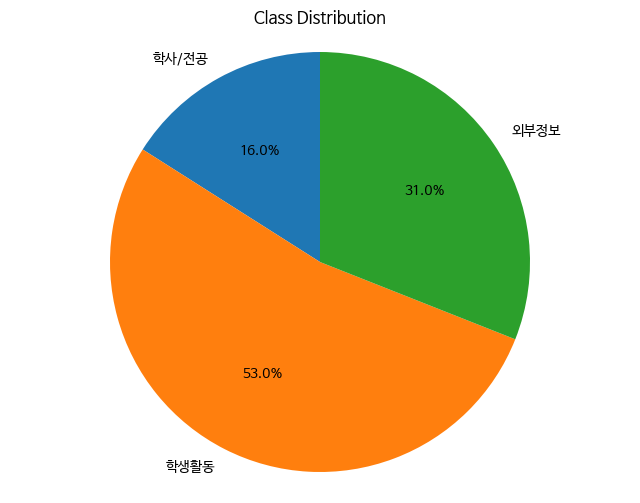

In [24]:
def plot_class(df):
  ## 분류 클래스별 개수 계산 및 순서 재정렬
  class_counts = df['class'].value_counts().reindex(['학사/전공', '학생활동', '외부정보'])

  plt.figure(figsize=(8, 6)) ## 그래프 크기 설정
  plt.pie(class_counts,
          labels=class_counts.index,
          autopct='%.1f%%', ## 퍼센트 표시 형식
          startangle=90, ## 시작 각도 설정
          )

  plt.title('Class Distribution') ## 그래프 제목 설정
  plt.axis('equal') ## 원형 비율 유지
  plt.show() ## 그래프 표시

plot_class(cs_df)

## 13-18 다른 학과의 분류 결과 시각화

In [25]:
def classify_ko(title):
  return classify('국어국문학과', title)

ko_df['class_analysis'] = ko_df['제목'].apply(classify_ko)
ko_df['class'] = ko_df['class_analysis'].apply(get_class)

def classify_law(title):
  return classify('법학과', title)

law_df['class_analysis'] = law_df['제목'].apply(classify_law)
law_df['class'] = law_df['class_analysis'].apply(get_class)

Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]



Processed prompts:   0%|          | 0/1 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

Processed prompts: 100%|██████████| 1/1 [00:03<00:00,  3.77s/it, est. speed input: 58.04 toks/s, output: 42.41 toks/s]

Processed prompts: 100%|██████████| 1/1 [00:03<00:00,  3.78s/it, est. speed input: 58.04 toks/s, output: 42.41 toks/s]


Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]



Processed prompts:   0%|          | 0/1 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

Processed prompts: 100%|██████████| 1/1 [00:03<00:00,  3.07s/it, est. speed input: 74.02 toks/s, output: 42.72 toks/s]

Processed prompts: 100%|██████████| 1/1 [00:03<00:00,  3.07s/it, est. speed input: 74.02 toks/s, output: 42.72 toks/s]


Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]



Processed prompts:   0%|          | 0/1 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

Processed prompts: 100%|██████████| 1/1 [00:01<00:00,  1.07s/it, est. speed input: 190.73 toks/s, output: 42.80 toks/s]

Processed prompts: 100%|██████████| 1/1 [00:01<00:00,  1.08s/it, est. speed input: 190.73 toks/s, output: 42.80 toks/s]


... (390 outputs left out)

Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]



Processed prompts:   0%|          | 0/1 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

Processed prompts: 100%|██████████| 1/1 [00:01<00:00,  1.43s/it, est. speed input: 143.70 toks/s, output: 43.25 toks/s]

Processed prompts: 100%|██████████| 1/1 [00:01<00:00,  1.44s/it, est. speed input: 143.70 toks/s, output: 43.25 toks/s]


Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]



Processed prompts:   0%|          | 0/1 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

Processed prompts: 100%|██████████| 1/1 [00:01<00:00,  1.15s/it, est. speed input: 184.02 toks/s, output: 42.73 toks/s]

Processed prompts: 100%|██████████| 1/1 [00:01<00:00,  1.15s/it, est. speed input: 184.02 toks/s, output: 42.73 toks/s]


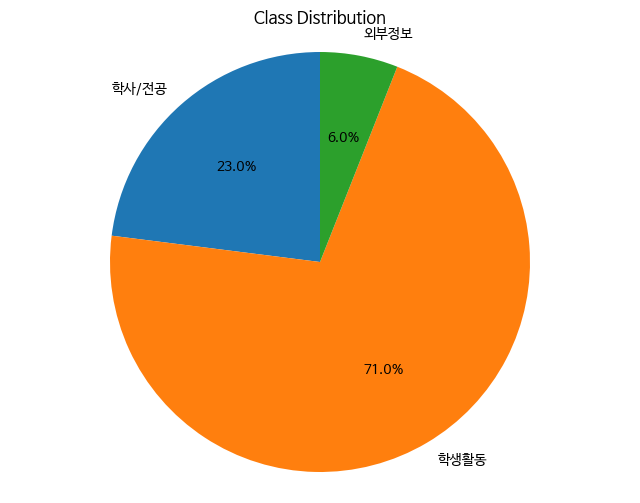

In [26]:
plot_class(ko_df)

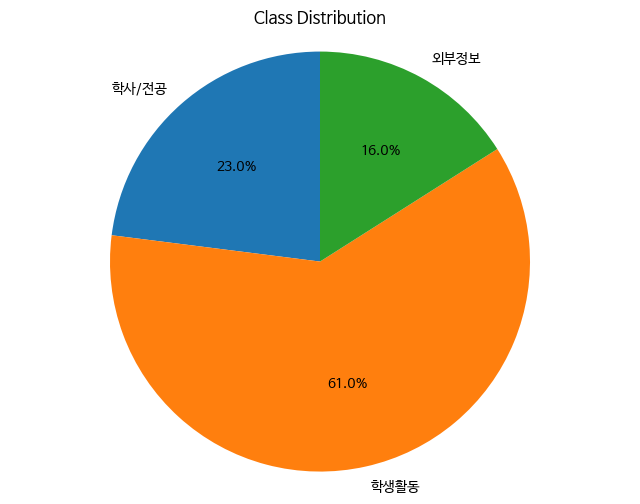

In [27]:
plot_class(law_df)